# Построение бейзлайн-модели для кейса №5: Доставка еды

## Часть 1. Загрузка данных и фильтрация по итогам EDA

По результатам EDA мы решили исключить из модели недоставленные заказы, поскольку они никак не помогают нам рассчитывать скорость. Также удаляем строки с нереалистичной скоростью доставки, поскольку они будут вносить лишний шум в модель

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('food_delivery_orders_dataset.csv')

df_delivered = df[df['order_status'] == 'Completed'].copy()
transit_time = df_delivered['actual_delivery_time_minutes'] - df_delivered['restaurant_preparation_time_minutes']
speed_kmh = df_delivered['distance_km'] / (transit_time / 60)

df_clean = df_delivered[(transit_time > 0) & (speed_kmh <= 60)].copy()

print(f'Исходный размер: {len(df)} строк')
print(f'Чистая выборка df_clean: {len(df_clean)} строк, {df_clean.shape[1]} столбцов')
print(f'Пропусков в таргете: {df_clean["actual_delivery_time_minutes"].isna().sum()}')

Исходный размер: 50000 строк
Чистая выборка df_clean: 48914 строк, 37 столбцов
Пропусков в таргете: 0


## Часть 2. Подготовка признаков и разбиение выборки

### 2.1 Отбор признаков и кодирование категорий

Уберем из модели технические идентификаторы и сырые даты, поскольку они никак не влияют на скорость доставки. Далее откажемся от районов доставки, так как у нас уже есть точная дистанция в километрах и город. Также на оценку времени доставки не могут повлиять факторы, которые произодуйт в будущем: оценка клиента, факт опоздания, чаевые. Потому что на момент заказа мы их банально не знаем и не можем учитывать. На этапе EDA, мы заметили сильную взаимосвязь между стоимостью заказа и временем готовки, поэтому для избежания дублирования факторов решили оставить просто кол-во блюд. 

Старый прогноз также удаляем из данных, но сохраним в отдельную переменную, чтобы потом было с чем сравнивать. Несмотря на то, что в EDA мы увидели, что опыт и рейтинг курьера не коррелируют со временем доставки, эти признаки пока оставим, поскольку они явно были указаны в задании. Проверим их веса в регрессии. 

Также приведем категориальные признаки (погода, город, уровень пробок) в числовые столбцы, поскольку линейная модель работает только с цифрами. 

In [29]:
df_clean['traffic_level'] = pd.Categorical(df_clean['traffic_level'], categories=['Low', 'Medium', 'High'])
df_clean['weather'] = pd.Categorical(df_clean['weather'], categories=['Clear', 'Cloudy', 'Rain', 'Storm'])
df_clean['restaurant_type'] = pd.Categorical(df_clean['restaurant_type'], categories=['Fast Food', 'Casual Dining', 'Cafe', 'Fine Dining'])

feature_cols = [
    'distance_km',
    'restaurant_preparation_time_minutes',
    'items_count',
    'order_hour',
    'is_weekend',
    'restaurant_rating',
    'delivery_partner_experience_months',
    'delivery_partner_rating',
    'traffic_level',
    'weather',
    'restaurant_type',
    'city'
]

X = pd.get_dummies(df_clean[feature_cols], drop_first=True, dtype=int)
y = df_clean['actual_delivery_time_minutes']
platform_pred = df_clean['estimated_delivery_time_minutes']

print(f'Размер матрицы признаков X: {X.shape[0]} строк, {X.shape[1]} столбцов')
display(X.head(5))

Размер матрицы признаков X: 48914 строк, 19 столбцов


,distance_km,restaurant_preparation_time_minutes,items_count,order_hour,is_weekend,restaurant_rating,delivery_partner_experience_months,delivery_partner_rating,traffic_level_Medium,traffic_level_High,weather_Cloudy,weather_Rain,weather_Storm,restaurant_type_Casual Dining,restaurant_type_Cafe,restaurant_type_Fine Dining,city_City_B,city_City_C,city_City_D
0,1.1,25,4,15,1,4.4,14,4.4,1,0,0,1,0,1,0,0,0,1,0
1,2.5,12,2,20,0,4.4,44,4.7,0,1,1,0,0,0,1,0,0,0,0
2,11.8,11,1,18,0,4.8,1,5.0,0,1,1,0,0,0,0,0,0,1,0
3,5.4,12,1,16,0,3.9,50,4.3,0,0,1,0,0,0,0,0,0,0,0
4,6.1,9,1,18,0,3.5,21,4.0,1,0,0,1,0,1,0,0,1,0,0


После этих работ вместо 12 исходных признаков у нас получилось 19 числовых столбцов. Базовые значения категориальных признаков вроде ясной погоды или свободных дорог не указываем отдельно, поскольку они кодируются нулями и служат точкой отсчета.

### 2.2 Разделение на обучающую и тестовую выборки

Разделим всю выборку на обучающую и тестовую в пропорции 75/25. Зафиксируем параметр random_state=42 для воспроизводимости результата проверяющим и другими членами команды. Тут же разобьем старый прогноз в такой же пропорции, чтобы честно сравнивать ошибки. В наших данных не используютяс временные ряды, у нас отдельные независимые поездки, так что случайное перемешивание здесь подходит.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, platform_train, platform_test = train_test_split(
    X, y, platform_pred, test_size=0.25, random_state=42
)

print(f'Обучающая выборка (train): {X_train.shape[0]} заказов')
print(f'Тестовая выборка (test):   {X_test.shape[0]} заказов')

Обучающая выборка (train): 36685 заказов
Тестовая выборка (test):   12229 заказов


## Часть 3. Базовая линейная регрессия и масштабирование

### 3.1 Обучение модели и анализ сырых коэффициентов

Обучим базовую модель линейной регрессии на тренировочной выборке, затем получим предсказания для тестовых заказов и посмотрим, какие веса получились у признаков и какое смещение

In [31]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train, y_train)
y_pred_base = lm.predict(X_test)

coef_df = pd.DataFrame({
    'Признаки': X_train.columns,
    'Коэффициенты': lm.coef_.round(3)
})

print(f'Свободный член (intercept): {lm.intercept_:.3f}')
display(coef_df)

Свободный член (intercept): -5.663


,Признаки,Коэффициенты
0,distance_km,4.046
1,restaurant_preparation_time_minutes,1.003
2,items_count,-0.015
3,order_hour,-0.002
4,is_weekend,-0.004
5,restaurant_rating,-0.038
6,delivery_partner_experience_months,0.001
7,delivery_partner_rating,0.005
8,traffic_level_Medium,4.349
9,traffic_level_High,9.412


У нас получились довольно логичные коэффициенты в исходных единицах измерения. Например, единица приготовления блюда добавляет 1 минуту ко времени доставки. Каждый километр пути прибавляет 4 минуты, а сильные пробки увеличивают время доставки на 9.4 минуты относительно свободных дорог. Самую большую прибавку дает шторм - сразу плюс 13 минут по сравнению с ясной погодой. 

Но сравнивать эти признаки между собой сейчас некорректно, поскольку они измеряются в разных шкалах (минуты, километры, флаги, месяцы опыта). Для адекватной оценки приведем данные к единому масштабу. 

### 3.2 Масштабирование признаков и оценка их реальной важности

Приведем все признаки к единому масштабу с помощью StandardScaler, чтобы честно сравнивать силу их влияния на время доставки. Это не повлияет на сами предсказания, но позволит сделать веса более сравнивыми. 

Обучаем стандартизатор строго на тренировочной выборке, чтобы информация из теста не протекла в обучение

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

lm_scaled = LinearRegression()
lm_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = lm_scaled.predict(X_test_scaled)

print('Предсказания до и после масштабирования совпадают:', np.allclose(y_pred_base, y_pred_scaled))
print(f'Свободный член: {lm_scaled.intercept_:.3f} (среднее время на тренировочной выборке: {y_train.mean():.3f})')

coef_scaled_df = pd.DataFrame({
    'Признаки': X_train.columns,
    'Коэффициенты': lm_scaled.coef_.round(3)
}).sort_values(by='Коэффициенты', key=abs, ascending=False)

display(coef_scaled_df)

Предсказания до и после масштабирования совпадают: True
Свободный член: 35.270 (среднее время на тренировочной выборке: 35.270)


,Признаки,Коэффициенты
0,distance_km,11.221
1,restaurant_preparation_time_minutes,7.373
9,traffic_level_High,4.334
11,weather_Rain,2.132
8,traffic_level_Medium,2.122
12,weather_Storm,2.105
10,weather_Cloudy,0.769
16,city_City_B,0.058
13,restaurant_type_Casual Dining,-0.031
2,items_count,-0.030


Как и предполагали, предсказания до и после масштабирования совпадают. Свободный член после масштабирования стал равен среднему времени доставки на обучающей выборке. 

Зато картина важности признаков стала другой: главным фактором стала дистанция, на втором месте время готовки в ресторане, а дальше идут пробки и непогода. Шторм по важности опустился сильно ниже, даже ниже дождя и средних пробок. Это происходит потому, что штормовая погода хоть и даёт большую задержку, но встречается очень редко. 

Также показательно, что 12 столбцов имеют около нулевое влияние (в том числе опыт и рейтинг курьера) на уровне сотых долей минуты.

## Часть 4. Отбор признаков и оценка качества модели

На предыдущем шаге мы заметили, что 12 из 19 столбцов (включая опыт и рейтинг курьера, час заказа, тип города и ресторана) имеют почти нулевые веса. Проверим принцип экономности модели: оставим 7 действительно важных столбцов, обучим компактную регрессию и сравним метрики R2, MAE, RMSE между полной моделью, компактной версией и старым алгоритмом, который был в самой платформе. Причем будем сравнивать на одних и тех же тестовых данных.

In [33]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

compact_cols = [
    'distance_km',
    'restaurant_preparation_time_minutes',
    'traffic_level_Medium',
    'traffic_level_High',
    'weather_Cloudy',
    'weather_Rain',
    'weather_Storm'
]

lm_compact = LinearRegression()
lm_compact.fit(X_train[compact_cols], y_train)
y_pred_compact = lm_compact.predict(X_test[compact_cols])

metrics_df = pd.DataFrame([
    {
        'Модель': 'Старый алгоритм платформы',
        'Признаков': '-',
        'R2': round(r2_score(y_test, platform_test), 4),
        'MAE (мин)': round(mean_absolute_error(y_test, platform_test), 3),
        'RMSE (мин)': round(root_mean_squared_error(y_test, platform_test), 3)
    },
    {
        'Модель': 'Базовая регрессия (19 столбцов)',
        'Признаков': X_train.shape[1],
        'R2': round(r2_score(y_test, y_pred_base), 4),
        'MAE (мин)': round(mean_absolute_error(y_test, y_pred_base), 3),
        'RMSE (мин)': round(root_mean_squared_error(y_test, y_pred_base), 3)
    },
    {
        'Модель': 'Компактная регрессия (топ-7 столбцов)',
        'Признаков': len(compact_cols),
        'R2': round(r2_score(y_test, y_pred_compact), 4),
        'MAE (мин)': round(mean_absolute_error(y_test, y_pred_compact), 3),
        'RMSE (мин)': round(root_mean_squared_error(y_test, y_pred_compact), 3)
    }
])

display(metrics_df)

,Модель,Признаков,R2,MAE (мин),RMSE (мин)
0,Старый алгоритм платформы,-,0.7842,5.231,6.875
1,Базовая регрессия (19 столбцов),19,0.9363,2.751,3.734
2,Компактная регрессия (топ-7 столбцов),7,0.9364,2.749,3.732


Гипотеза полностью подтвердилась. После удаления 12 слабых столбцов качество модели не пострадало. Значит, характеристики курьера, город и тип ресторана действительно были лишним шумом. Компактная модель из 7 признаков предпочтительнее за счет своей простоты. 

Стоит также отметить, что даже такая простая линейная регрессия ошибается почти в два раза меньше страого алгоритма платформы, у которого средняя ошибка составляла 5.23 минуты, а R2 был всего 0.7842.

## Часть 5. Генерация новых признаков (Feature Engineering)

В ходе анализа мы заметили, что сильные пробки прибавляют 9.4 минуты к любому заказу, независимо от того, как далеко ехать. Может быть, курьеру нужно просто перейти дорогу и тогда влияние не будет таким сильным. Это происходит потому, что обычная линейная регрессия просто складывает признаки между собой.

В реальности такие факторы как непогода и пробки влияют на каждый километр пути. Чем дальше ехать, тем больше будет накапливаться задержка. Давайте попробуем добавить к нашей компактной выборке произведение дистанции на категории пробок и погоды. Также добавим отдельный признак одновременного сочетания осадков и пробок. Посмотрим, как поменяются метрики.

In [34]:
def add_physics_features(df_part):
    res = df_part[compact_cols].copy()
    res['dist_x_traffic_Medium'] = res['distance_km'] * res['traffic_level_Medium']
    res['dist_x_traffic_High'] = res['distance_km'] * res['traffic_level_High']
    res['dist_x_weather_Cloudy'] = res['distance_km'] * res['weather_Cloudy']
    res['dist_x_weather_Rain'] = res['distance_km'] * res['weather_Rain']
    res['dist_x_weather_Storm'] = res['distance_km'] * res['weather_Storm']
    res['bad_weather_x_high_traffic'] = (
        ((res['weather_Rain'] == 1) | (res['weather_Storm'] == 1)) &
        (res['traffic_level_High'] == 1)
    ).astype(int)
    return res

X_train_fe = add_physics_features(X_train)
X_test_fe = add_physics_features(X_test)

lm_fe = LinearRegression()
lm_fe.fit(X_train_fe, y_train)
y_pred_fe = lm_fe.predict(X_test_fe)

fe_row = pd.DataFrame([{
    'Модель': 'Регрессия + Feature Engineering',
    'Признаков': X_train_fe.shape[1],
    'R2': round(r2_score(y_test, y_pred_fe), 4),
    'MAE (мин)': round(mean_absolute_error(y_test, y_pred_fe), 3),
    'RMSE (мин)': round(root_mean_squared_error(y_test, y_pred_fe), 3)
}])

metrics_all_df = pd.concat([metrics_df, fe_row], ignore_index=True)
display(metrics_all_df)

,Модель,Признаков,R2,MAE (мин),RMSE (мин)
0,Старый алгоритм платформы,-,0.7842,5.231,6.875
1,Базовая регрессия (19 столбцов),19,0.9363,2.751,3.734
2,Компактная регрессия (топ-7 столбцов),7,0.9364,2.749,3.732
3,Регрессия + Feature Engineering,13,0.9704,2.028,2.545


Немного логически подумав, мы мощно увеличили качество модели даже без смены алгоритма. R2 вырос с 0.9364 до 0.9704, MAE снизилась с 2.75 до 2.03 минуты, а RMSE упал сразу с 3.73 до 2.55 минуты. Сильное падение RMSE говорит нам о том, что модель стала реже ошибаться именно на дальних заказах в плохую погоду и пробки. 

## Часть 6. Визуальная диагностика ошибок и итоги

Однако одни только метрики не позволяют увидеть характер ошибок модели. Может быть, она постоянно завышает или систематически занижает прогнозы в одну сторону. Давайте построим два проверочных графика для нашей финальной модели: сравнение реальных и предсказанных значений относительно идеальной диагонали, а также распределение остатков (разницы между фактом и прогнозом).

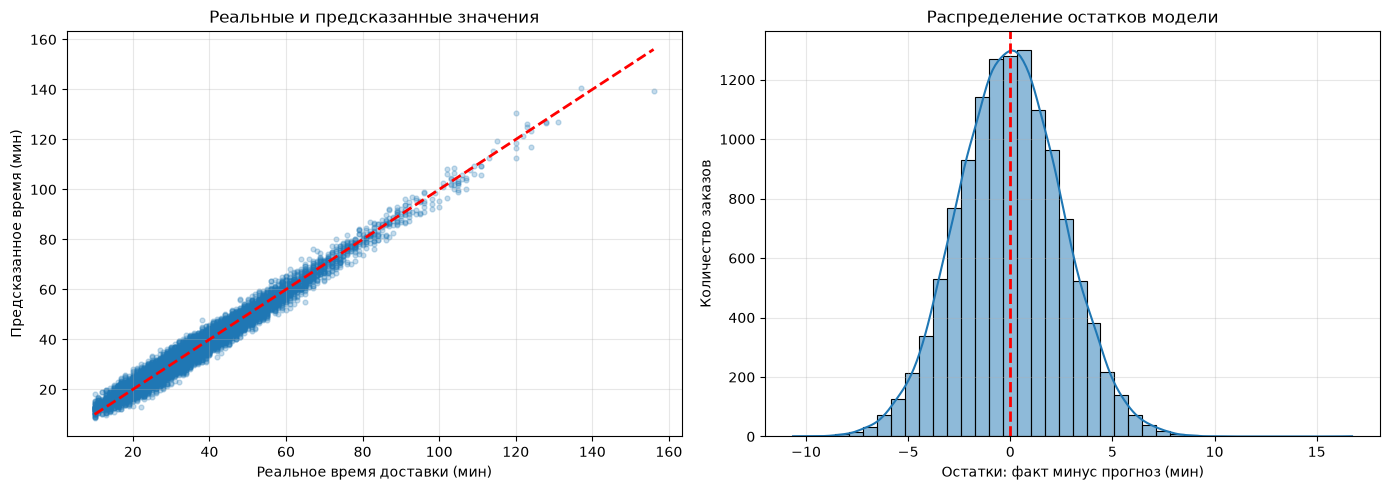

Средний остаток: -0.007 мин
Доля заказов с ошибкой в пределах 5 минут: 95.1%


In [35]:
residuals = y_test - y_pred_fe

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_fe, alpha=0.25, s=12)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', linewidth=2)
axes[0].set_xlabel('Реальное время доставки (мин)')
axes[0].set_ylabel('Предсказанное время (мин)')
axes[0].set_title('Реальные и предсказанные значения')
axes[0].grid(True, alpha=0.3)

sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Остатки: факт минус прогноз (мин)')
axes[1].set_ylabel('Количество заказов')
axes[1].set_title('Распределение остатков модели')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

within_5 = (residuals.abs() <= 5).mean() * 100
print(f'Средний остаток: {residuals.mean():.3f} мин')
print(f'Доля заказов с ошибкой в пределах 5 минут: {within_5:.1f}%')

Видим, что на левом графике точно достаточно плотно и равномерно ложатся вдоль красной линии, без каких-либо заметных изгибов. 

На правом графике остатки образуют симметричный колокол вокруг нуля, так что модель одинаково сбалансированно ошибается и в плюс и в минус. Также заметим, что более чем в 95% тестовых заказов модель укладывается в коридор 5 минут. 

## Итоги построения бейзлайн-модели

В этой работе мы построили бейзлайн на линейной регрессии для прогноза времени доставки по очищенной выборке из 48 914 завершенных заказов. После масштабирования признаков на обучающей выборке выяснилось, что время поездки в основном зависит от четырех групп факторов: дистанции маршрута, времени готовки в ресторане, уровня пробок и погоды. А вот характеристики курьера (опыт и рейтинг), город, тип заведения и количество блюд получили почти нулевые веса. Их удаление позволило сократить модель с 19 до 7 столбцов без потери качества (R2 остался на уровне 0.9364, а средняя ошибка MAE составила 2.75 минуты).

Заметный скачок точности дал Feature Engineering с опорой на обычную физику движения. Когда мы добавили произведения дистанции на категории пробок и погоды, а также флаг сочетания осадков и сильных пробок, R2 вырос до 0.9704, средняя ошибка MAE снизилась до 2.03 минуты, а RMSE упал с 3.73 до 2.55 минуты. Для сравнения, старый алгоритм самой платформы на тех же тестовых заказах ошибался в среднем на 5.23 минуты при R2 = 0.7842.

Проверка графиков показала, что остатки распределены симметричным колоколом вокруг нуля без систематического завышения или занижения прогнозов, а более 95% заказов укладываются в коридор ошибки 5 минут. Эту модель с новыми признаками фиксируем как основной ориентир качества перед переходом к более сложным алгоритмам на следующих этапах проекта.